# Titanic Exploratory Data Analysis

**Dataset:** Titanic: Machine Learning from Disaster (Kaggle), `train.csv`, 891 passengers

**Goal:** clean the data, summarize it, and find out which passengers were most likely to survive.

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

## Phase 1: Setup and First Look

Import the libraries, load `train.csv` and check its size, data types and basic statistics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print(df.shape)
df.info()

(891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


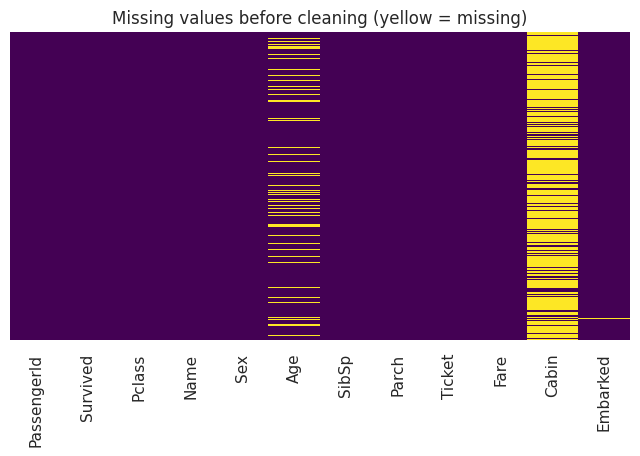

In [4]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing values before cleaning (yellow = missing)")
plt.show()

dtypes_before = df.dtypes

In [5]:
df.describe().round(2)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


In [6]:
df.describe(exclude="number")

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


**What I noticed**
- The dataset has 891 passengers and 12 columns.
- `Age` (714 non-null), `Cabin` (204) and `Embarked` (889) have missing values.
- About 38% of passengers survived (mean of `Survived` is 0.38).
- Median fare is 14.45, but the maximum is 512.33, so `Fare` has strong outliers.
- `Name`, `Sex`, `Ticket`, `Cabin` and `Embarked` are text columns. `Sex` has 2 values and `Embarked` has 3.


## Phase 2: Data Cleaning

**Plan for the missing values**
- **Age** (177 missing, 19.9%): fill with the median age of the passenger's class and sex, because age differs between groups.
- **Embarked** (2 missing): fill with the most common port.
- **Cabin** (687 missing, 77.1%): too empty to fill, so replace it with a Yes/No column (`Has_Cabin`) and drop the original.
- **Duplicates:** none found.

In [7]:
missing = pd.DataFrame({
    "missing": df.isnull().sum(),
    "percent": (df.isnull().mean() * 100).round(1)
})
missing[missing["missing"] > 0]

,missing,percent
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [9]:
# Age: median of each Pclass + Sex group
df["Age"] = df["Age"].fillna(df.groupby(["Pclass", "Sex"])["Age"].transform("median"))

# Embarked: most frequent port
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Cabin: keep only whether the passenger had one recorded
df["Has_Cabin"] = df["Cabin"].notnull().astype(int)
df = df.drop(columns=["Cabin"])

print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


In [10]:
# Categorical columns
df["Pclass"] = df["Pclass"].astype("category")
df["Sex"] = df["Sex"].astype("category")
df["Embarked"] = df["Embarked"].astype("category")

# Readable labels for charts
df["Survival"] = df["Survived"].map({0: "Died", 1: "Survived"})
df["Embarked_Port"] = df["Embarked"].map({"C": "Cherbourg", "Q": "Queenstown", "S": "Southampton"})

df.dtypes

PassengerId         int64
Survived            int64
Pclass           category
Name                  str
Sex              category
Age               float64
SibSp               int64
Parch               int64
Ticket                str
Fare              float64
Embarked         category
Has_Cabin           int64
Survival              str
Embarked_Port    category
dtype: object

In [11]:
order = list(dtypes_before.index) + [c for c in df.columns if c not in dtypes_before.index]
pd.DataFrame({"before": dtypes_before.astype(str), "after": df.dtypes.astype(str)}).reindex(order).fillna("-")

,before,after
PassengerId,int64,int64
Survived,int64,int64
Pclass,int64,category
Name,str,str
Sex,str,category
Age,float64,float64
SibSp,int64,int64
Parch,int64,int64
Ticket,str,str
Fare,float64,float64


In [12]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "Young Adult", "Adult", "Senior"]
)

df[["Age", "AgeGroup", "SibSp", "Parch", "FamilySize", "IsAlone"]].head()

,Age,AgeGroup,SibSp,Parch,FamilySize,IsAlone
0,22.0,Young Adult,1,0,2,0
1,38.0,Adult,1,0,2,0
2,26.0,Young Adult,0,0,1,1
3,35.0,Young Adult,1,0,2,0
4,35.0,Young Adult,0,0,1,1


**Cleaning summary**
- No missing values are left (0).
- `Pclass`, `Sex` and `Embarked` were converted to categorical types.
- New columns: `Survival` and `Embarked_Port` (readable labels), `FamilySize`, `IsAlone` and `AgeGroup` (Child, Teen, Young Adult, Adult, Senior).
- 177 ages were imputed, so age-group results are approximate.
- A cleaned copy (including the `Title` column added in Phase 3) is saved as `titanic_cleaned.csv`.


## Phase 3: Summary Statistics and Group Insights

How does survival differ by gender, class, age group, port of embarkation and cabin?

In [13]:
print("Overall survival rate:", round(df["Survived"].mean() * 100, 1), "%")
df["Survival"].value_counts()

Overall survival rate: 38.4 %


Survival
Died        549
Survived    342
Name: count, dtype: int64

In [14]:
df.groupby("Sex", observed=True)["Survived"].agg(["count", "sum", "mean"]).round(3)

,count,sum,mean
Sex,,,
female,314,233,0.742
male,577,109,0.189


In [15]:
df.groupby("Pclass", observed=True)["Survived"].agg(["count", "sum", "mean"]).round(3)

,count,sum,mean
Pclass,,,
1,216,136,0.630
2,184,87,0.473
3,491,119,0.242


In [16]:
df.groupby(["Pclass", "Sex"], observed=True)["Survived"].agg(["count", "mean"]).round(3)

count   mean
Pclass Sex                 
1      female     94  0.968
       male      122  0.369
2      female     76  0.921
       male      108  0.157
3      female    144  0.500
       male      347  0.135

**Key findings so far**
- Survival fell sharply with class: 63.0% in 1st class, 47.3% in 2nd and 24.2% in 3rd.
- Gender had an even bigger effect: 1st-class women survived at 96.8% while 3rd-class men survived at only 13.5%.
- A 3rd-class woman (50.0%) was more likely to survive than a 1st-class man (36.9%), which fits the "women and children first" evacuation order.

In [17]:
print(df.groupby("AgeGroup", observed=True)["Survived"].agg(["count", "mean"]).round(3))
print()
print(df.groupby("Embarked_Port", observed=True)["Survived"].agg(["count", "mean"]).round(3))
print()
print(df.groupby("Has_Cabin")["Survived"].mean().round(3))

             count   mean
AgeGroup                 
Child           69  0.580
Teen            70  0.429
Young Adult    514  0.358
Adult          216  0.384
Senior          22  0.227

               count   mean
Embarked_Port              
Cherbourg        168  0.554
Queenstown        77  0.390
Southampton      646  0.339

Has_Cabin
0    0.300
1    0.667
Name: Survived, dtype: float64


In [18]:
print(df.groupby("IsAlone")["Survived"].mean().round(3))
print()
print(df.groupby("Survival")[["Age", "Fare"]].mean().round(1))

IsAlone
0    0.506
1    0.304
Name: Survived, dtype: float64

           Age  Fare
Survival            
Died      29.7  22.1
Survived  28.1  48.4


In [19]:
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
rare = df["Title"].value_counts()[lambda s: s < 10].index
df["Title"] = df["Title"].replace(rare, "Rare")
df.groupby("Title")["Survived"].agg(["count", "mean"]).round(3)

,count,mean
Title,,
Master,40,0.575
Miss,185,0.703
Mr,517,0.157
Mrs,126,0.794
Rare,23,0.348


In [20]:
from scipy.stats import chi2_contingency
for col in ["Sex", "Pclass"]:
    p = chi2_contingency(pd.crosstab(df[col], df["Survived"]))[1]
    print(f"{col}: p = {p:.2e}")

Sex: p = 1.20e-58
Pclass: p = 4.55e-23


In [21]:
df.to_csv("titanic_cleaned.csv", index=False)

**Key findings**
- Passengers travelling with family survived at 50.6%, compared with 30.4% for those travelling alone.
- Survivors paid an average fare of $48.4, more than twice the $22.1 paid by those who died, which reflects the class effect seen earlier.
- Average age was similar for both groups (28.1 vs 29.7), so age alone does not explain survival.
- Children survived at 58%, while seniors survived at only 22.7% (n=22, so treat with caution).
- Cherbourg passengers survived at 55.4%, vs 33.9% for Southampton.
- Passengers with a recorded cabin survived far more often, but this partly reflects how records were kept.
- Title shows the same pattern: Mrs 79.4%, Miss 70.3%, Master (boys) 57.5%, Mr 15.7%.
- Chi-square tests confirm that sex and class are significantly related to survival (p < 0.001).


## Phase 4: Visualizations

Charts of the passenger mix, age, fares and the patterns behind survival.

In [22]:
import os
os.makedirs("figures", exist_ok=True)

def save(name):
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

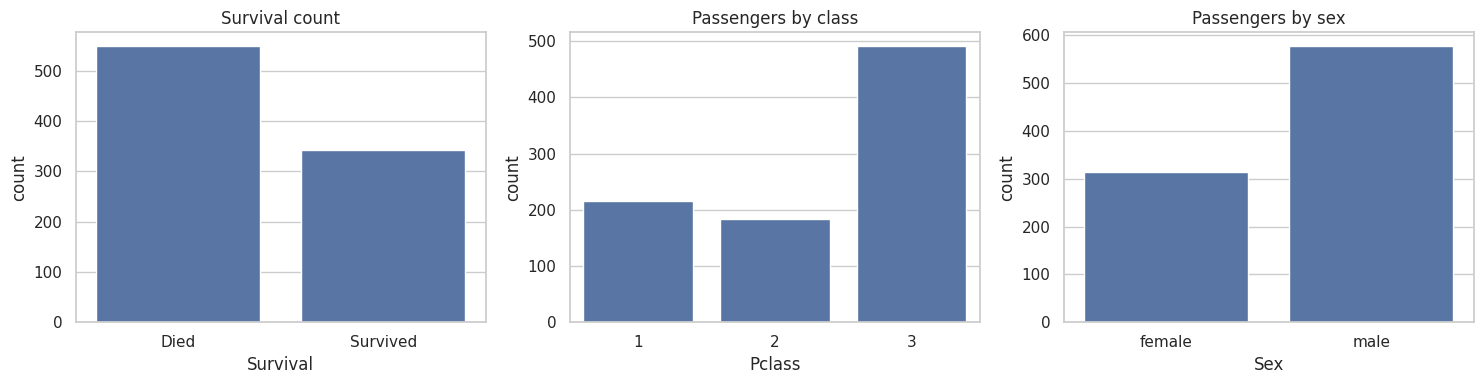

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x="Survival", ax=axes[0]); axes[0].set_title("Survival count")
sns.countplot(data=df, x="Pclass", ax=axes[1]); axes[1].set_title("Passengers by class")
sns.countplot(data=df, x="Sex", ax=axes[2]); axes[2].set_title("Passengers by sex")
plt.tight_layout()
save("01_overview")
plt.show()

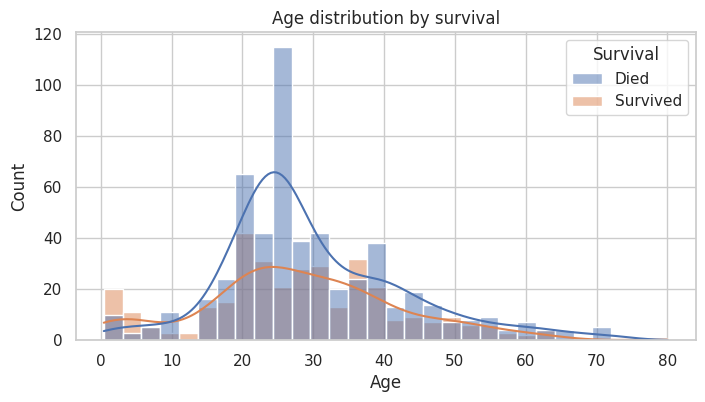

In [24]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="Age", hue="Survival", bins=30, kde=True)
plt.title("Age distribution by survival")
save("02_age")
plt.show()

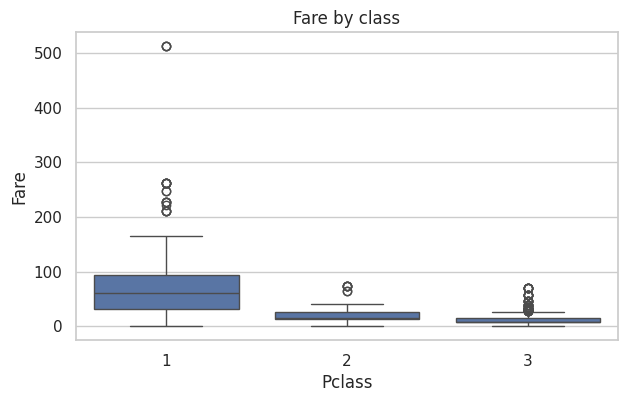

In [25]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Pclass", y="Fare")
plt.title("Fare by class")
save("03_fare")
plt.show()

Fare outliers: 116


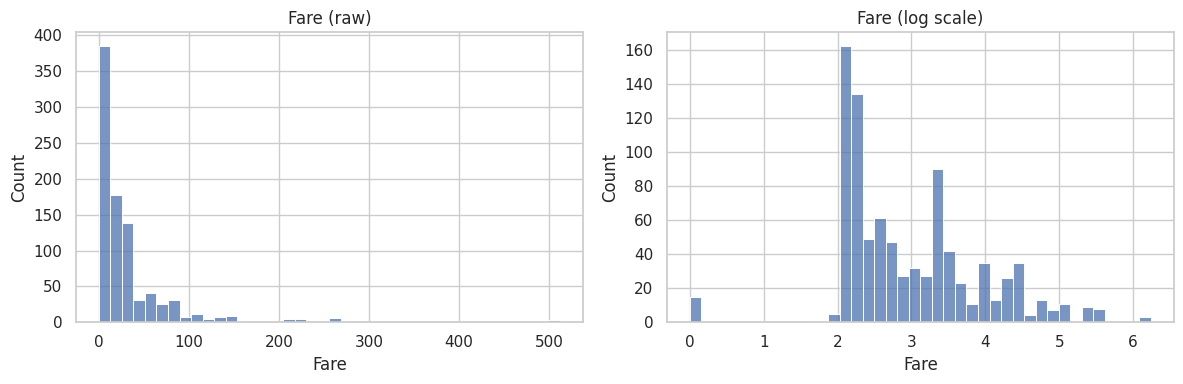

In [26]:
q1, q3 = df["Fare"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print("Fare outliers:", (df["Fare"] > upper).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Fare"], bins=40, ax=axes[0]); axes[0].set_title("Fare (raw)")
sns.histplot(np.log1p(df["Fare"]), bins=40, ax=axes[1]); axes[1].set_title("Fare (log scale)")
plt.tight_layout()
save("03b_fare_log")
plt.show()

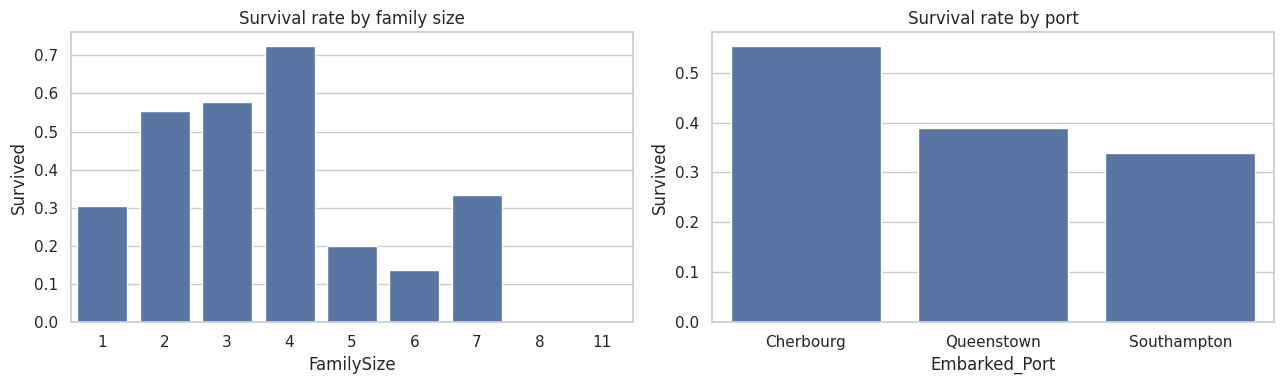

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=df, x="FamilySize", y="Survived", errorbar=None, ax=axes[0])
axes[0].set_title("Survival rate by family size")
sns.barplot(data=df, x="Embarked_Port", y="Survived", errorbar=None, ax=axes[1])
axes[1].set_title("Survival rate by port")
plt.tight_layout()
save("04_family_port")
plt.show()

**What the charts show**
- Fewer passengers survived (342) than died (549), and most passengers were in 3rd class and male.
- Children under 12 survived more than they died, unlike most other ages.
- First-class fares are much higher and have extreme outliers (up to $512).
- Survival is best for families of 2 to 4, and lowest for people travelling alone or in very large families.
- Passengers who boarded at Cherbourg survived more often than those from Southampton.
- 116 passengers are fare outliers (above about $65). I kept them because they are real first-class fares, and the log scale reduces the skew.


## Phase 5: Correlation Analysis

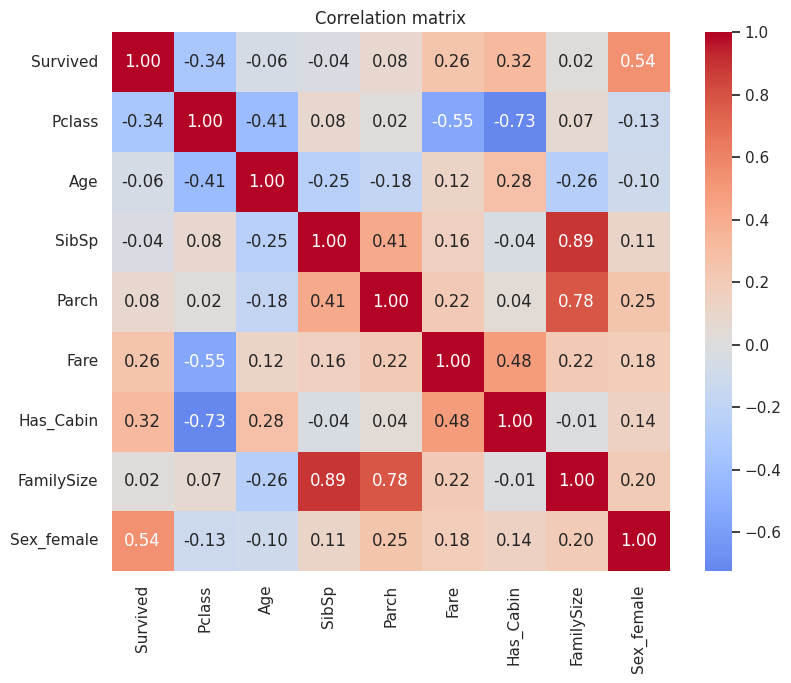

In [28]:
corr_df = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "Has_Cabin", "FamilySize"]].copy()
corr_df["Pclass"] = corr_df["Pclass"].astype(int)
corr_df["Sex_female"] = (df["Sex"] == "female").astype(int)

plt.figure(figsize=(9, 7))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
save("05_correlation")
plt.show()

In [29]:
corr_df.corr()["Survived"].drop("Survived").sort_values(ascending=False).round(2)

Sex_female    0.54
Has_Cabin     0.32
Fare          0.26
Parch         0.08
FamilySize    0.02
SibSp        -0.04
Age          -0.06
Pclass       -0.34
Name: Survived, dtype: float64

**What the correlations show**
- The strongest links with survival are `Sex_female` (+0.54), `Pclass` (-0.34), `Has_Cabin` (+0.32) and `Fare` (+0.26).
- `Age` (-0.06) and `FamilySize` (+0.02) are weak in a straight-line sense. Family size still matters in a non-linear way: families of 2 to 4 did best.
- `Fare`, `Pclass` and `Has_Cabin` are related to each other, because all three reflect wealth.
- Pearson correlation is only a rough guide for yes/no and ordered columns.


## Phase 6 (Bonus): Survival Rates

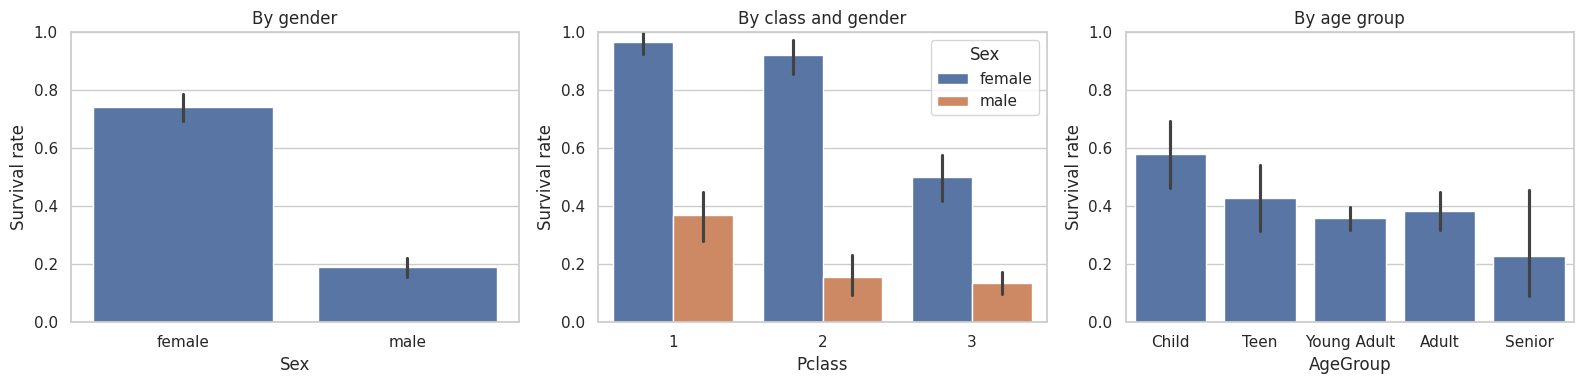

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=df, x="Sex", y="Survived", errorbar=("ci", 95), ax=axes[0]); axes[0].set_title("By gender")
sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex", errorbar=("ci", 95), ax=axes[1]); axes[1].set_title("By class and gender")
sns.barplot(data=df, x="AgeGroup", y="Survived", errorbar=("ci", 95), ax=axes[2]); axes[2].set_title("By age group")
for ax in axes:
    ax.set_ylim(0, 1)
    ax.set_ylabel("Survival rate")
plt.tight_layout()
save("06_survival_bars")
plt.show()

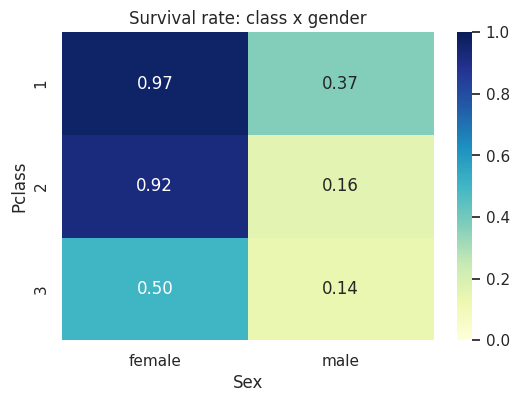

In [31]:
pv = df.pivot_table(values="Survived", index="Pclass", columns="Sex", aggfunc="mean", observed=True)
plt.figure(figsize=(6, 4))
sns.heatmap(pv, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Survival rate: class x gender")
save("07_heatmap_class_gender")
plt.show()

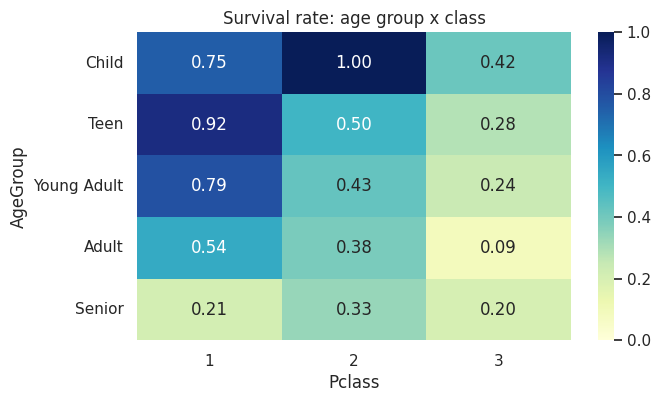

In [32]:
pv2 = df.pivot_table(values="Survived", index="AgeGroup", columns="Pclass", aggfunc="mean", observed=True)
plt.figure(figsize=(7, 4))
sns.heatmap(pv2, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Survival rate: age group x class")
save("08_heatmap_age_class")
plt.show()

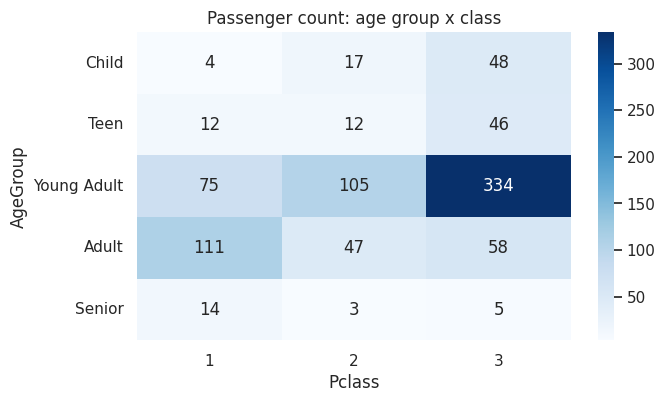

In [33]:
cnt = df.pivot_table(values="Survived", index="AgeGroup", columns="Pclass", aggfunc="count", observed=True)
plt.figure(figsize=(7, 4))
sns.heatmap(cnt, annot=True, fmt="d", cmap="Blues")
plt.title("Passenger count: age group x class")
save("09_heatmap_counts")
plt.show()

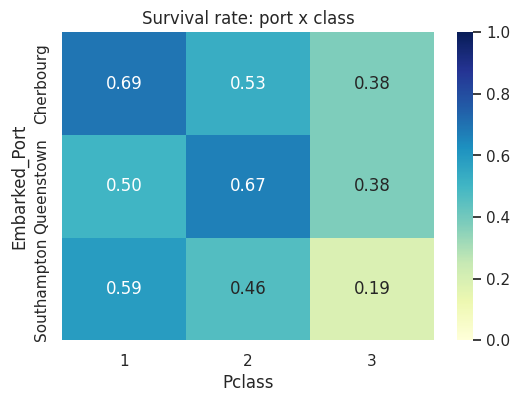

In [34]:
pv3 = df.pivot_table(values="Survived", index="Embarked_Port", columns="Pclass", aggfunc="mean", observed=True)
plt.figure(figsize=(6, 4))
sns.heatmap(pv3, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Survival rate: port x class")
save("10_heatmap_port_class")
plt.show()

**What the bonus plots show**
- Women survived at about 74% vs about 19% for men.
- 1st- and 2nd-class women were above 90%, while 3rd-class men were at only 13.5%.
- Survival fell from 1st to 3rd class within each sex, so class mattered on top of gender.
- Error bars are 95% confidence intervals. Wide bars mean small groups, such as seniors.
- The count heatmap shows several age-class cells have very few passengers, so read those rates carefully.


## Conclusions
1. Sex was the strongest factor: women survived at about 74% vs about 19% for men.
2. Class was second: 63% (1st) vs 24% (3rd). Class mattered within each sex.
3. Children (58%) and small families of 2 to 4 survived best. Solo travellers (30%) and very large families did worst.
4. Cherbourg passengers survived more, largely because more of them were in 1st class.
5. Limitations: 177 ages were imputed, Cabin was 77% missing, and these are correlations, not proof of cause.
